# Demographics and Migration — When a Rate Is Not Comparable

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-Year (pinned)

D01 measured poverty. D03 measured education. Both compared states by a single rate, and both
were careful about whether the *uncertainty* in a rate permitted the comparison.

This notebook asks a prior question: **is the rate comparable at all?**

A poverty rate for a state is a weighted average of its age-specific poverty rates, weighted by
that state's own age structure. Two states can differ in the headline rate while every
age-specific rate is identical — and, in the real published data, two states can differ in one
direction on the headline rate and in the **opposite** direction once age structure is held
fixed. That is not a rounding artefact. It is the defining hazard of comparing crude rates, and
it is why every vital-statistics agency publishes age-standardised rates alongside crude ones.

The correction is applied here to real ACS data, and the honest result is reported: for state
poverty rates the correction is usually **small**, occasionally **decisive**, and there is no way
to know which case you are in without doing it.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

1. **Derive** the identity that makes a crude rate a composition-weighted average of
   group-specific rates, and verify it numerically on real data.
2. **Compute** a directly age-standardised rate, and check it against the property that defines
   it — a population standardised to its own composition is unchanged.
3. **Decompose** the difference between two crude rates exactly into a rate component and a
   composition component (Kitagawa), and read the sign pattern that marks a reversal.
4. **Search** the full set of state pairs for orderings that reverse under standardisation, and
   **filter** them by whether either ordering is distinguishable given the published margins of
   error.
5. **Propagate** margins of error through a weighted sum of proportions, and bound the result
   under both extreme correlation assumptions.
6. **State** what standardisation does not fix: residual within-group heterogeneity, the
   dependence of the answer on the choice of standard, and the universe the table actually covers.

## Prerequisites

**Knowledge.** D01 (rates from ACS counts, margins of error). D03 (propagation and significance
testing) is assumed. No modelling background is needed; the only algebra used is the weighted
average and its exact decomposition.

**Setup.** `CENSUS_API_KEY` in the environment, or in the file `KRL_SECRETS_PATH` points at. The
data layer reads only the four public-data key names it recognises and refuses every other name
before it opens the file, so a secrets file holding database URLs and unrelated tokens is never
parsed for them.

**Packages.** `pandas`, `numpy`, `matplotlib`, and `krl_tutorials_data`.

## Data Provenance

Table **B17001 — Poverty Status in the Past 12 Months by Sex by Age**, ACS 2023 5-Year.

| Variables | Published label (verbatim) | Role |
|---|---|---|
| `B17001_001E` | Estimate!!Total: | universe |
| `B17001_002E` | …below poverty level: | published marginal, used as a check |
| `B17001_031E` | …at or above poverty level: | published marginal, used as a check |
| `B17001_004E`–`_016E` | …below poverty level:!!Male:!!*age* | 13 age cells |
| `B17001_018E`–`_030E` | …below poverty level:!!Female:!!*age* | 13 age cells |
| `B17001_033E`–`_045E` | …at or above poverty level:!!Male:!!*age* | 13 age cells |
| `B17001_047E`–`_059E` | …at or above poverty level:!!Female:!!*age* | 13 age cells |

plus the `…M` margin-of-error variant of every one of the above.

**The standard population is taken from B17001 itself, at the national level.** This is not a
convenience. B17001's universe is *the population for whom poverty status is determined*, which
excludes people in institutional group quarters, military barracks and college dormitories, and
unrelated children under 15. The age distribution in `B01001` (the general sex-by-age table)
therefore describes a **different population** — roughly eight million people different — and its
age brackets do not align with B17001's either. Standardising one universe by another's
composition would introduce exactly the error this technique exists to remove.

**Block offsets were read, not inferred.** The "at or above" section starts at `_031`, so its male
age cells start at `_033` — one position further along than splitting 59 variables evenly would
suggest. The audited corpus contains a defect of precisely this shape, where `B27001_005E` was
assumed to mean "males under 6" and did not, producing a figure wrong by roughly fifty times.

In [1]:
"""Configuration. Age groups and B17001 block offsets, taken from the published table."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import (
    fetch_acs_wide, DataAccessError, CENSUS_GET_CEILING,
)
from krl_tutorials_data.standardization import (
    StandardPopulation, crude_rate, direct_standardized_rate,
    standardized_rate_estimate, standardized_rate_bounds, kitagawa_decomposition,
)
from krl_tutorials_data.uncertainty import (
    Estimate, aggregate_moe, aggregate_moe_bounds, proportion_moe,
    difference_is_significant,
)

ACS_VINTAGE = 2023
UNIT_OF_ANALYSIS = "state (50 states + DC + Puerto Rico)"

# The 13 B17001 age groups, in published order. Short display names on the left,
# the verbatim published label suffix on the right.
AGE_GROUPS = (
    ("Under 5",     "Under 5 years"),
    ("5",           "5 years"),
    ("6 to 11",     "6 to 11 years"),
    ("12 to 14",    "12 to 14 years"),
    ("15",          "15 years"),
    ("16 to 17",    "16 and 17 years"),
    ("18 to 24",    "18 to 24 years"),
    ("25 to 34",    "25 to 34 years"),
    ("35 to 44",    "35 to 44 years"),
    ("45 to 54",    "45 to 54 years"),
    ("55 to 64",    "55 to 64 years"),
    ("65 to 74",    "65 to 74 years"),
    ("75 plus",     "75 years and over"),
)
AGE_NAMES = tuple(short for short, _ in AGE_GROUPS)
N_AGE = len(AGE_GROUPS)

# Offsets read from the published variable list. See the provenance note above:
# the "at or above" male block starts at _033, not _032.
BLOCK_START = {
    ("below poverty level", "Male"): 4,
    ("below poverty level", "Female"): 18,
    ("at or above poverty level", "Male"): 33,
    ("at or above poverty level", "Female"): 47,
}
STATUS_STEM = {
    "below poverty level": "Income in the past 12 months below poverty level:",
    "at or above poverty level": "Income in the past 12 months at or above poverty level:",
}

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

print(f"Unit of analysis : {UNIT_OF_ANALYSIS}")
print(f"Vintage          : ACS {ACS_VINTAGE} 5-Year (pinned)")
print(f"Age groups       : {N_AGE}")
print(f"Blocks           : {len(BLOCK_START)} (2 poverty statuses x 2 sexes)")
print(f"Estimate cells   : {N_AGE * len(BLOCK_START)} age-sex-status cells + 3 marginals")

Unit of analysis : state (50 states + DC + Puerto Rico)
Vintage          : ACS 2023 5-Year (pinned)
Age groups       : 13
Blocks           : 4 (2 poverty statuses x 2 sexes)
Estimate cells   : 52 age-sex-status cells + 3 marginals


### One request will not carry this table

The Census API accepts at most 50 comma-separated names in `get`, counting `NAME`. This notebook
needs 55 estimates and 55 margins of error — 110 names. Over the ceiling the API returns a bare
`HTTP 400` with no explanatory body, which is indistinguishable from a malformed geography, so
the ceiling is enforced in the data layer and the request is split.

Splitting is where a silent error would live. A batch that returned a different set or order of
geographies would misalign every downstream rate without raising anything. The join therefore
checks that every batch returned the identical geography key set and merges on that key
explicitly, rather than trusting response order.

In [2]:
def cell_codes(status: str, sex: str, suffix: str) -> list[str]:
    """The 13 consecutive B17001 variable codes for one status-sex block."""
    start = BLOCK_START[(status, sex)]
    return [f"B17001_{start + i:03d}{suffix}" for i in range(N_AGE)]


def published_label(status: str, sex: str, age_label: str) -> str:
    return f"Estimate!!Total:!!{STATUS_STEM[status]}!!{sex}:!!{age_label}"


VARIABLES: dict[str, str] = {
    "B17001_001E": "Estimate!!Total:",
    "B17001_002E": f"Estimate!!Total:!!{STATUS_STEM['below poverty level']}",
    "B17001_031E": f"Estimate!!Total:!!{STATUS_STEM['at or above poverty level']}",
}
for _status in STATUS_STEM:
    for _sex in ("Male", "Female"):
        for _code, (_short, _age_label) in zip(
            cell_codes(_status, _sex, "E"), AGE_GROUPS
        ):
            VARIABLES[_code] = published_label(_status, _sex, _age_label)
# Every estimate carries its published margin of error.
for _code in list(VARIABLES):
    VARIABLES[_code[:-1] + "M"] = "Margin of Error for " + VARIABLES[_code]

print(f"Variables requested : {len(VARIABLES)}")
print(f"Census `get` ceiling: {CENSUS_GET_CEILING} names including NAME")
print(f"Minimum batches     : {-(-len(VARIABLES) // (CENSUS_GET_CEILING - 1))}")
print("\nSpot check of constructed labels:")
for _c in ("B17001_004E", "B17001_033E", "B17001_059E", "B17001_033M"):
    print(f"  {_c}  {VARIABLES[_c]}")

Variables requested : 110
Census `get` ceiling: 50 names including NAME
Minimum batches     : 3

Spot check of constructed labels:
  B17001_004E  Estimate!!Total:!!Income in the past 12 months below poverty level:!!Male:!!Under 5 years
  B17001_033E  Estimate!!Total:!!Income in the past 12 months at or above poverty level:!!Male:!!Under 5 years
  B17001_059E  Estimate!!Total:!!Income in the past 12 months at or above poverty level:!!Female:!!75 years and over
  B17001_033M  Margin of Error for Estimate!!Total:!!Income in the past 12 months at or above poverty level:!!Male:!!Under 5 years


In [3]:
try:
    nation, prov_us = fetch_acs_wide(
        year=ACS_VINTAGE, variables=VARIABLES, geography="us:*",
    )
    states, prov_state = fetch_acs_wide(
        year=ACS_VINTAGE, variables=VARIABLES, geography="state:*",
    )
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

print(f"National frame : {nation.shape[0]} row  x {nation.shape[1]} columns")
print(f"State frame    : {states.shape[0]} rows x {states.shape[1]} columns")
print()
print(prov_state.render())

National frame : 1 row  x 112 columns
State frame    : 52 rows x 112 columns

Source      : U.S. Census Bureau - American Community Survey (acs/acs5)
Vintage     : 2023  (pinned)
Endpoint    : https://api.census.gov/data/2023/acs/acs5
Retrieved   : 2026-09-18T12:16:47+00:00
Shape       : 52 rows x 112 cols
Payload hash: e60878ee205f41c6...  (canonical-rows)
Data mode   : EMPIRICAL
Variables   :
              B17001_001E      Estimate!!Total:
              B17001_002E      Estimate!!Total:!!Income in the past 12 months below poverty level:
              B17001_031E      Estimate!!Total:!!Income in the past 12 months at or above poverty level:
              B17001_004E      Estimate!!Total:!!Income in the past 12 months below poverty level:!!Male:!!Under 5 years
              B17001_005E      Estimate!!Total:!!Income in the past 12 months below poverty level:!!Male:!!5 years
              B17001_006E      Estimate!!Total:!!Income in the past 12 months below poverty level:!!Male:!!6 to 11

### Reconciling against the published marginals

The 52 age–sex cells should sum to the two published status totals, and those to the universe.
They are published independently, so agreement is evidence that the block offsets are right —
and disagreement would be evidence that they are not, before any rate is computed from them.

This check is the reason the two marginal variables were requested at all. They are never used in
an analysis; they exist to falsify the parsing.

In [4]:
def block_sum(row: pd.Series, status: str, suffix: str) -> np.ndarray:
    """Per-age-group totals for one poverty status, summed across sexes.

    Estimates add. Margins of error combine in quadrature, which is the Census
    formula for an aggregated count.
    """
    male = [row[c] for c in cell_codes(status, "Male", suffix)]
    female = [row[c] for c in cell_codes(status, "Female", suffix)]
    if suffix == "E":
        return np.array([m + f for m, f in zip(male, female)], dtype=float)
    return np.array(
        [aggregate_moe([Estimate(0.0, m), Estimate(0.0, f)]).moe
         for m, f in zip(male, female)],
        dtype=float,
    )


def age_profile(row: pd.Series) -> dict[str, np.ndarray]:
    """Per-age-group poor counts, population at risk, and both margins."""
    poor = block_sum(row, "below poverty level", "E")
    nonpoor = block_sum(row, "at or above poverty level", "E")
    poor_m = block_sum(row, "below poverty level", "M")
    nonpoor_m = block_sum(row, "at or above poverty level", "M")
    at_risk = poor + nonpoor
    at_risk_m = np.array(
        [aggregate_moe([Estimate(0.0, a), Estimate(0.0, b)]).moe
         for a, b in zip(poor_m, nonpoor_m)],
        dtype=float,
    )
    return {"poor": poor, "poor_moe": poor_m,
            "at_risk": at_risk, "at_risk_moe": at_risk_m}


_recon = []
for _frame, _tag in ((nation, "United States"), (states, "state")):
    for _, _row in _frame.iterrows():
        _p = age_profile(_row)
        _recon.append({
            "geography": _row["NAME"],
            "cells_below": _p["poor"].sum(),
            "published_below": float(_row["B17001_002E"]),
            "cells_at_or_above": (_p["at_risk"] - _p["poor"]).sum(),
            "published_at_or_above": float(_row["B17001_031E"]),
            "cells_total": _p["at_risk"].sum(),
            "published_total": float(_row["B17001_001E"]),
        })
recon = pd.DataFrame(_recon)
recon["below_ok"] = recon.cells_below == recon.published_below
recon["above_ok"] = recon.cells_at_or_above == recon.published_at_or_above
recon["total_ok"] = recon.cells_total == recon.published_total

_n = len(recon)
_all_ok = int((recon.below_ok & recon.above_ok & recon.total_ok).sum())
print(f"Geographies reconciled exactly : {_all_ok} / {_n}")
print(f"  below-poverty marginal       : {int(recon.below_ok.sum())} / {_n}")
print(f"  at-or-above marginal         : {int(recon.above_ok.sum())} / {_n}")
print(f"  universe total               : {int(recon.total_ok.sum())} / {_n}")
if _all_ok != _n:
    _bad = recon.loc[~(recon.below_ok & recon.above_ok & recon.total_ok)]
    print("\nGeographies that did not reconcile - the block offsets are wrong:")
    print(_bad[["geography", "cells_total", "published_total"]].to_string(index=False))
    raise SystemExit(
        "B17001 cells do not sum to the published marginals. Stopping before any "
        "rate is computed from a parse that has been falsified."
    )

Geographies reconciled exactly : 53 / 53
  below-poverty marginal       : 53 / 53
  at-or-above marginal         : 53 / 53
  universe total               : 53 / 53


## The crude rate is a weighted average, and the weights are the problem

For a geography with age groups $a$, let $p_a$ be the number in poverty, $n_a$ the population at
risk, $r_a = p_a / n_a$ the age-specific rate and $w_a = n_a / \sum_g n_g$ the share of the
population in that group. Then

$$\text{crude rate} \;=\; \frac{\sum_a p_a}{\sum_a n_a} \;=\; \sum_a w_a\, r_a .$$

Nothing about this is approximate — it is an identity, verified numerically below. Its
consequence is that the headline rate confounds two entirely different things: how poor each age
group is, and how many people are in each age group. Only the first is usually what someone means
when they compare two states.

The confounding has force only if $r_a$ actually varies with age. It does.

In [5]:
us_row = nation.iloc[0]
us = age_profile(us_row)
us_rates = us["poor"] / us["at_risk"]
us_weights = us["at_risk"] / us["at_risk"].sum()

us_crude = crude_rate(us["poor"], us["at_risk"])
identity = float(np.dot(us_weights, us_rates))

profile = pd.DataFrame({
    "age_group": AGE_NAMES,
    "at_risk": us["at_risk"],
    "poor": us["poor"],
    "rate": us_rates,
    "share": us_weights,
    "contribution": us_weights * us_rates,
})
print(profile.to_string(
    index=False,
    formatters={"at_risk": "{:,.0f}".format, "poor": "{:,.0f}".format,
                "rate": "{:.3%}".format, "share": "{:.2%}".format,
                "contribution": "{:.4f}".format}))
print()
print(f"crude rate  sum(poor)/sum(at_risk) : {us_crude:.6%}")
print(f"identity    sum(w_a * r_a)         : {identity:.6%}")
print(f"absolute difference                : {abs(us_crude - identity):.3e}")
print(f"age-specific rates span            : {us_rates.min():.2%} "
      f"({AGE_NAMES[int(us_rates.argmin())]}) to {us_rates.max():.2%} "
      f"({AGE_NAMES[int(us_rates.argmax())]}), a ratio of {us_rates.max() / us_rates.min():.2f}x")

age_group    at_risk      poor    rate  share contribution
  Under 5 18,590,246 3,268,155 17.580%  5.73%       0.0101
        5  3,853,967   658,235 17.079%  1.19%       0.0020
  6 to 11 24,221,594 4,030,770 16.641%  7.46%       0.0124
 12 to 14 12,842,006 1,965,490 15.305%  3.96%       0.0061
       15  4,381,726   678,226 15.479%  1.35%       0.0021
 16 to 17  8,583,097 1,229,002 14.319%  2.64%       0.0038
 18 to 24 27,145,550 5,118,439 18.856%  8.36%       0.0158
 25 to 34 44,775,243 5,217,101 11.652% 13.80%       0.0161
 35 to 44 42,895,249 4,457,767 10.392% 13.22%       0.0137
 45 to 54 40,454,168 3,631,285  8.976% 12.46%       0.0112
 55 to 64 42,244,910 4,481,044 10.607% 13.02%       0.0138
 65 to 74 32,889,794 3,160,937  9.611% 10.13%       0.0097
  75 plus 21,689,597 2,493,594 11.497%  6.68%       0.0077

crude rate  sum(poor)/sum(at_risk) : 12.444280%
identity    sum(w_a * r_a)         : 12.444280%
absolute difference                : 4.163e-17
age-specific rates span       

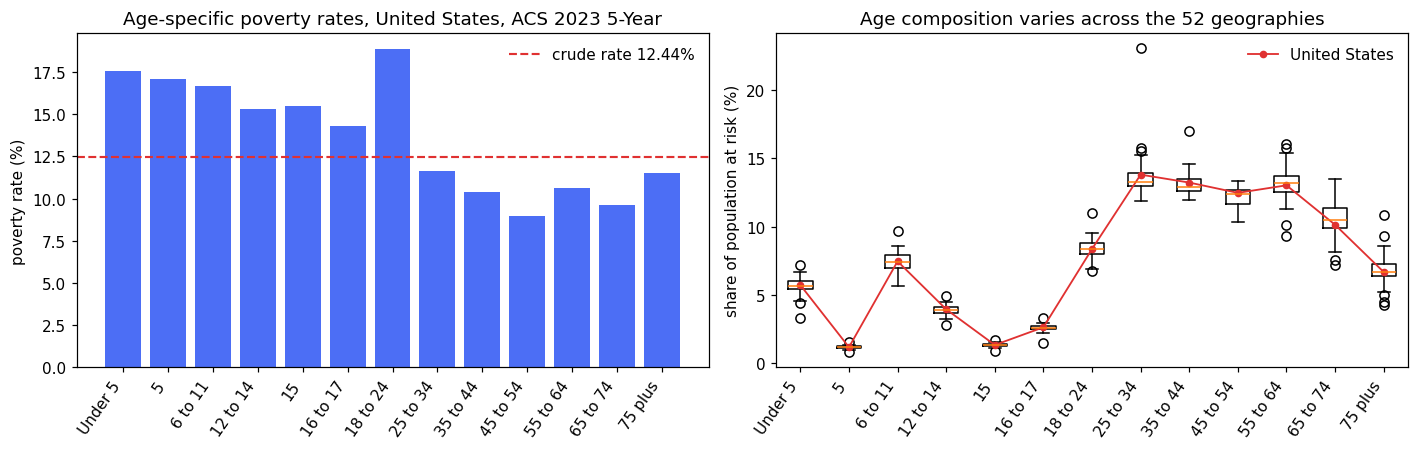

Widest cross-state spread in population share, by age group:
  25 to 34   11.88% (West Virginia) to 23.02% (District of Columbia)  spread 11.14%
  55 to 64    9.34% (Utah) to 16.06% (New Hampshire)  spread 6.71%
  75 plus     4.28% (Alaska) to 10.86% (Puerto Rico)  spread 6.58%
  65 to 74    7.20% (Utah) to 13.44% (Maine)  spread 6.25%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].bar(range(N_AGE), us_rates * 100, color="#4c6ef5")
axes[0].axhline(us_crude * 100, color="#e03131", lw=1.4, ls="--",
                label=f"crude rate {us_crude:.2%}")
axes[0].set_xticks(range(N_AGE)); axes[0].set_xticklabels(AGE_NAMES, rotation=55, ha="right")
axes[0].set_ylabel("poverty rate (%)")
axes[0].set_title(f"Age-specific poverty rates, United States, ACS {ACS_VINTAGE} 5-Year")
axes[0].legend(frameon=False)

_spread = pd.DataFrame({
    s: age_profile(r)["at_risk"] / age_profile(r)["at_risk"].sum()
    for s, r in ((r_["NAME"], r_) for _, r_ in states.iterrows())
})
axes[1].boxplot([_spread.loc[i] * 100 for i in range(N_AGE)], tick_labels=AGE_NAMES)
axes[1].plot(range(1, N_AGE + 1), us_weights * 100, "o-", color="#e03131",
             lw=1.2, ms=4, label="United States")
axes[1].set_xticklabels(AGE_NAMES, rotation=55, ha="right")
axes[1].set_ylabel("share of population at risk (%)")
axes[1].set_title("Age composition varies across the 52 geographies")
axes[1].legend(frameon=False)

plt.tight_layout(); plt.show()

_range = (_spread.max(axis=1) - _spread.min(axis=1))
print("Widest cross-state spread in population share, by age group:")
for _i in np.argsort(-_range.to_numpy())[:4]:
    _lo, _hi = _spread.loc[_i].idxmin(), _spread.loc[_i].idxmax()
    print(f"  {AGE_NAMES[_i]:<10} {_spread.loc[_i].min():6.2%} ({_lo}) to "
          f"{_spread.loc[_i].max():6.2%} ({_hi})  spread {_range.iloc[_i]:.2%}")

## Direct standardisation

Direct standardisation replaces each geography's own weights with a **shared** set, so the
comparison isolates the $r_a$:

$$\text{ASR} \;=\; \sum_a w_a^{\text{std}} \, r_a .$$

The choice of standard is a real analytic decision and changes the numbers, which is why the
standard is carried on the object rather than passed as a bare array. Here it is the national
B17001 age distribution — the same universe as the geographies being standardised.

The property that defines the operation is that standardising a population to **its own**
composition must return its crude rate exactly. That is checked below rather than assumed.

In [7]:
STANDARD = StandardPopulation.from_counts(
    name=f"United States, ACS {ACS_VINTAGE} 5-Year, B17001 poverty universe",
    labels=AGE_NAMES,
    counts=us["at_risk"],
)

# The defining property, checked on every geography: standardising a population
# to its own age composition reproduces its crude rate.
_self_errors = []
for _, _row in states.iterrows():
    _p = age_profile(_row)
    _own = StandardPopulation.from_counts("own composition", AGE_NAMES, _p["at_risk"])
    _self_errors.append(abs(
        direct_standardized_rate(_p["poor"], _p["at_risk"], _own)
        - crude_rate(_p["poor"], _p["at_risk"])
    ))
print(f"Standard: {STANDARD.name}")
print(f"Weights sum to {STANDARD.weights.sum():.12f}")
print(f"Self-standardisation identity, worst error over {len(states)} geographies: "
      f"{max(_self_errors):.3e}")

Standard: United States, ACS 2023 5-Year, B17001 poverty universe
Weights sum to 1.000000000000
Self-standardisation identity, worst error over 52 geographies: 5.551e-17


In [8]:
rows = []
for _, row in states.iterrows():
    p = age_profile(row)
    events = [Estimate(v, m) for v, m in zip(p["poor"], p["poor_moe"])]
    at_risk = [Estimate(v, m) for v, m in zip(p["at_risk"], p["at_risk_moe"])]

    crude_est = Estimate(
        crude_rate(p["poor"], p["at_risk"]),
        proportion_moe(aggregate_moe(events), aggregate_moe(at_risk)),
    )
    asr_est = standardized_rate_estimate(events, at_risk, STANDARD)
    asr_lo, asr_hi = standardized_rate_bounds(events, at_risk, STANDARD)

    shares = p["at_risk"] / p["at_risk"].sum()
    rows.append({
        "name": row["NAME"],
        "crude": crude_est.value, "crude_moe": crude_est.moe,
        "asr": asr_est.value, "asr_moe": asr_est.moe,
        "asr_moe_worst": asr_hi.moe,
        "share_under_18": shares[:6].sum(),
        "share_65_plus": shares[11:].sum(),
        "_crude_est": crude_est, "_asr_est": asr_est,
        "_asr_worst": asr_hi, "_poor": p["poor"], "_at_risk": p["at_risk"],
    })

panel = pd.DataFrame(rows)
panel["delta_pp"] = (panel.asr - panel.crude) * 100
panel["rank_crude"] = panel.crude.rank(ascending=False).astype(int)
panel["rank_asr"] = panel.asr.rank(ascending=False).astype(int)
panel["rank_shift"] = panel.rank_crude - panel.rank_asr

print(f"Geographies standardised : {len(panel)}")
print(f"National crude rate      : {us_crude:.4%}")
print(f"Median crude MOE         : {panel.crude_moe.median() * 100:.3f} pp")
print(f"Median standardised MOE  : {panel.asr_moe.median() * 100:.3f} pp "
      f"(worst-case correlation: {panel.asr_moe_worst.median() * 100:.3f} pp)")
print(f"Mean absolute rank shift : {panel.rank_shift.abs().mean():.2f} places")
print(f"Largest rank shift       : {panel.rank_shift.abs().max()} places")
print(f"Geographies moving >= 5  : {int((panel.rank_shift.abs() >= 5).sum())}")
print(f"Largest rate change      : {panel.delta_pp.abs().max():.2f} pp")

Geographies standardised : 52
National crude rate      : 12.4443%
Median crude MOE         : 0.146 pp
Median standardised MOE  : 0.145 pp (worst-case correlation: 0.498 pp)
Mean absolute rank shift : 0.81 places
Largest rank shift       : 3 places
Geographies moving >= 5  : 0
Largest rate change      : 1.17 pp


### Reading this honestly

The correction is small. That is the finding, and it is worth more than a dramatic one would be.

State poverty rates are not like mortality rates. Mortality rises by orders of magnitude across
the age range, so a few percentage points of difference in the share aged 75+ moves a crude death
rate enormously. Poverty's age gradient is comparatively shallow — the ratio printed above, not a
hundredfold — and state age structures, while they do differ, do not differ enough to exploit it.

A notebook that set out to prove standardisation is essential would have picked mortality. The
point of applying it here, where it mostly does not matter, is that **the size of the correction
is not knowable in advance**; it is an output of the calculation, not a reason to skip it. And the
aggregate being small does not mean it is small everywhere, which the next section takes up.

In [9]:
_top = panel.reindex(panel.delta_pp.abs().sort_values(ascending=False).index).head(10)
print("Largest standardisation effects")
print(_top[["name", "crude", "asr", "delta_pp", "rank_crude", "rank_asr",
            "share_under_18", "share_65_plus"]].to_string(
    index=False,
    formatters={"crude": "{:.3%}".format, "asr": "{:.3%}".format,
                "delta_pp": "{:+.2f}".format,
                "share_under_18": "{:.1%}".format, "share_65_plus": "{:.1%}".format}))

_young = panel.loc[panel.share_under_18.idxmax()]
_old = panel.loc[panel.share_65_plus.idxmax()]
print(f"\nYoungest population at risk : {_young['name']} "
      f"({_young.share_under_18:.1%} under 18), crude {_young.crude:.3%} -> "
      f"standardised {_young.asr:.3%} ({_young.delta_pp:+.2f} pp)")
print(f"Oldest population at risk   : {_old['name']} "
      f"({_old.share_65_plus:.1%} aged 65+), crude {_old.crude:.3%} -> "
      f"standardised {_old.asr:.3%} ({_old.delta_pp:+.2f} pp)")
print("\nCorrelation of the standardisation effect with age structure:")
print(f"  with share under 18 : {np.corrcoef(panel.share_under_18, panel.delta_pp)[0, 1]:+.3f}")
print(f"  with share 65+      : {np.corrcoef(panel.share_65_plus, panel.delta_pp)[0, 1]:+.3f}")

Largest standardisation effects
                name   crude     asr delta_pp  rank_crude  rank_asr share_under_18 share_65_plus
District of Columbia 14.531% 15.699%    +1.17          10         8          19.1%         12.8%
         Puerto Rico 41.553% 42.475%    +0.92           1         1          16.8%         22.7%
       West Virginia 16.641% 17.073%    +0.43           5         5          20.3%         20.8%
                Utah  8.557%  8.128%    -0.43          51        51          28.5%         11.7%
               Texas 13.804% 13.499%    -0.30          12        14          25.5%         13.2%
               Maine 10.781% 11.070%    +0.29          33        31          18.4%         21.8%
        North Dakota 10.581% 10.305%    -0.28          37        39          24.2%         15.9%
            Oklahoma 15.333% 15.088%    -0.25           9        10          24.4%         16.1%
            Delaware 10.726% 10.953%    +0.23          35        33          21.1%         20.1

## Order reversals

An average effect of under a rank is compatible with individual comparisons flipping outright.
The full set of $\binom{52}{2}$ ordered pairs is searched for sign reversals — pairs where A has
the higher crude rate and B the higher standardised rate.

A reversal found this way is not yet a finding. Both orderings have to be **distinguishable given
the margins of error**, or the flip is a rearrangement of noise. Both filters are applied, and
both counts are reported, because the gap between them is the substance of this section.

In [10]:
reversals = []
for i in range(len(panel)):
    for j in range(i + 1, len(panel)):
        a, b = panel.iloc[i], panel.iloc[j]
        if (a.crude - b.crude) * (a.asr - b.asr) >= 0:
            continue
        crude_sig, _ = difference_is_significant(a["_crude_est"], b["_crude_est"])
        asr_sig, _ = difference_is_significant(a["_asr_est"], b["_asr_est"])
        asr_sig_worst, _ = difference_is_significant(a["_asr_worst"], b["_asr_worst"])
        reversals.append({
            "a": a["name"], "b": b["name"],
            "crude_a": a.crude, "crude_b": b.crude,
            "asr_a": a.asr, "asr_b": b.asr,
            "crude_distinguishable": crude_sig,
            "asr_distinguishable": asr_sig,
            "asr_distinguishable_worst_case": asr_sig_worst,
            "_ia": i, "_ib": j,
        })
rev = pd.DataFrame(reversals)
n_pairs = len(panel) * (len(panel) - 1) // 2
survivors = rev.loc[rev.crude_distinguishable & rev.asr_distinguishable]

print(f"Pairs examined                                  : {n_pairs}")
print(f"Orderings that reverse under standardisation    : {len(rev)}")
print(f"  ... with a distinguishable crude ordering     : {int(rev.crude_distinguishable.sum())}")
print(f"  ... with a distinguishable standardised one   : {int(rev.asr_distinguishable.sum())}")
print(f"  ... with both distinguishable                 : {len(survivors)}")
print(f"  ... both, under worst-case MOE correlation    : "
      f"{int((survivors.crude_distinguishable & survivors.asr_distinguishable_worst_case).sum())}")
print(f"\nReversals that are a rearrangement of sampling noise: "
      f"{len(rev) - len(survivors)} of {len(rev)}")

Pairs examined                                  : 1326
Orderings that reverse under standardisation    : 24
  ... with a distinguishable crude ordering     : 3
  ... with a distinguishable standardised one   : 5
  ... with both distinguishable                 : 1
  ... both, under worst-case MOE correlation    : 0

Reversals that are a rearrangement of sampling noise: 23 of 24


In [11]:
if survivors.empty:
    print("No reversal in this vintage survives both margin-of-error filters.")
    print("The technique still applies; this particular dataset does not exhibit one.")
else:
    for _, s in survivors.iterrows():
        a, b = panel.iloc[s["_ia"]], panel.iloc[s["_ib"]]
        split = kitagawa_decomposition(a["_poor"], a["_at_risk"], b["_poor"], b["_at_risk"])
        print(f"{a['name']}  vs  {b['name']}")
        print(f"  crude        {a.crude:.3%} +/- {a.crude_moe:.3%}   "
              f"{b.crude:.3%} +/- {b.crude_moe:.3%}   "
              f"-> {a['name'] if a.crude > b.crude else b['name']} is higher")
        print(f"  standardised {a.asr:.3%} +/- {a.asr_moe:.3%}   "
              f"{b.asr:.3%} +/- {b.asr_moe:.3%}   "
              f"-> {a['name'] if a.asr > b.asr else b['name']} is higher")
        print(f"  Kitagawa decomposition of the crude gap "
              f"({split.difference * 100:+.4f} pp):")
        print(f"    rate component        {split.rate_effect * 100:+.4f} pp   "
              f"(differences in age-specific rates)")
        print(f"    composition component {split.composition_effect * 100:+.4f} pp   "
              f"(differences in age structure)")
        print(f"    identity residual     {split.residual:.2e}")
        print(f"    composition share of the gap: {split.composition_share:.3f}")
        print(f"  survives worst-case MOE correlation: "
              f"{bool(s['crude_distinguishable'] and s['asr_distinguishable_worst_case'])}")
        print()

District of Columbia  vs  Oklahoma
  crude        14.531% +/- 0.448%   15.333% +/- 0.128%   -> Oklahoma is higher
  standardised 15.699% +/- 0.480%   15.088% +/- 0.124%   -> District of Columbia is higher
  Kitagawa decomposition of the crude gap (-0.8027 pp):
    rate component        +0.0051 pp   (differences in age-specific rates)
    composition component -0.8079 pp   (differences in age structure)
    identity residual     -3.47e-18
    composition share of the gap: 1.006
  survives worst-case MOE correlation: False



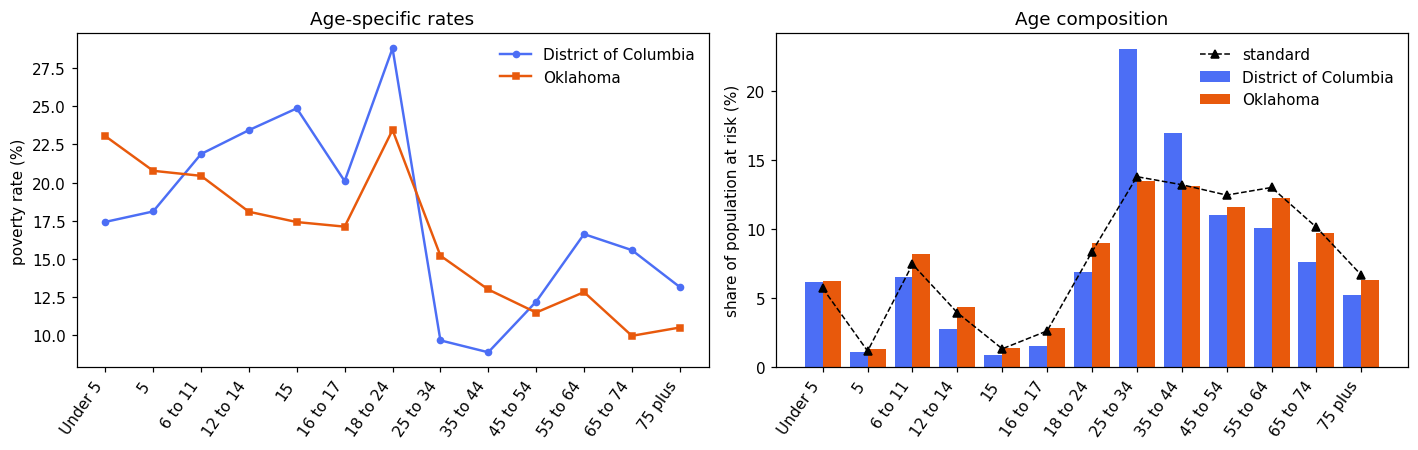

Age groups whose rates differ by less than one percentage point: 1 of 13
Largest age-specific gap: 7.44 pp (15)
Largest composition gap : 9.51 pp (25 to 34)

Rate component, term by term (these sum to +0.0051 pp):
  age groups favouring District of Columbia: +2.0178 pp
  age groups favouring Oklahoma: -2.0127 pp
  gross movement (sum of absolute terms): 4.0305 pp
  net as a fraction of gross: 0.0013

The age-specific rates are far apart in both directions; the near-zero
rate component is cancellation between age groups, not agreement between
them. A cancellation this near-exact is fragile to the vintage.


In [12]:
if not survivors.empty:
    s = survivors.iloc[0]
    a, b = panel.iloc[s["_ia"]], panel.iloc[s["_ib"]]
    ra = a["_poor"] / a["_at_risk"]
    rb = b["_poor"] / b["_at_risk"]
    wa = a["_at_risk"] / a["_at_risk"].sum()
    wb = b["_at_risk"] / b["_at_risk"].sum()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    x = np.arange(N_AGE)
    axes[0].plot(x, ra * 100, "o-", lw=1.6, ms=4, label=a["name"], color="#4c6ef5")
    axes[0].plot(x, rb * 100, "s-", lw=1.6, ms=4, label=b["name"], color="#e8590c")
    axes[0].set_xticks(x); axes[0].set_xticklabels(AGE_NAMES, rotation=55, ha="right")
    axes[0].set_ylabel("poverty rate (%)")
    axes[0].set_title("Age-specific rates")
    axes[0].legend(frameon=False)

    axes[1].bar(x - 0.2, wa * 100, width=0.4, label=a["name"], color="#4c6ef5")
    axes[1].bar(x + 0.2, wb * 100, width=0.4, label=b["name"], color="#e8590c")
    axes[1].plot(x, STANDARD.weights * 100, "k^--", lw=1.0, ms=5, label="standard")
    axes[1].set_xticks(x); axes[1].set_xticklabels(AGE_NAMES, rotation=55, ha="right")
    axes[1].set_ylabel("share of population at risk (%)")
    axes[1].set_title("Age composition")
    axes[1].legend(frameon=False)
    plt.tight_layout(); plt.show()

    _closer = int((np.abs(ra - rb) < 0.01).sum())
    print(f"Age groups whose rates differ by less than one percentage point: "
          f"{_closer} of {N_AGE}")
    print(f"Largest age-specific gap: {np.abs(ra - rb).max() * 100:.2f} pp "
          f"({AGE_NAMES[int(np.abs(ra - rb).argmax())]})")
    print(f"Largest composition gap : {np.abs(wa - wb).max() * 100:.2f} pp "
          f"({AGE_NAMES[int(np.abs(wa - wb).argmax())]})")

    # A rate component near zero does NOT mean the age-specific rates agree.
    # Here it means the age-group differences cancel. Show the cancellation
    # rather than leave a reader to infer similarity from a small total.
    split = kitagawa_decomposition(a["_poor"], a["_at_risk"], b["_poor"], b["_at_risk"])
    terms = ((wa + wb) / 2.0) * (ra - rb)
    pos, neg = terms[terms > 0].sum(), terms[terms < 0].sum()
    print(f"\nRate component, term by term (these sum to "
          f"{split.rate_effect * 100:+.4f} pp):")
    print(f"  age groups favouring {a['name']}: {pos * 100:+.4f} pp")
    print(f"  age groups favouring {b['name']}: {neg * 100:+.4f} pp")
    print(f"  gross movement (sum of absolute terms): "
          f"{np.abs(terms).sum() * 100:.4f} pp")
    print(f"  net as a fraction of gross: "
          f"{abs(split.rate_effect) / np.abs(terms).sum():.4f}")
    print("\nThe age-specific rates are far apart in both directions; the near-zero")
    print("rate component is cancellation between age groups, not agreement between")
    print("them. A cancellation this near-exact is fragile to the vintage.")

## What standardisation does not fix

Standardisation removes confounding by the variable it standardises on, and nothing else. Three
limits are checkable here rather than merely assertable.

**The answer depends on the standard.** An age-standardised rate is not a property of a
geography; it is a property of a geography *and a standard*. Two analysts using different
standards produce different numbers, and neither is wrong. Rates standardised to different
populations are not comparable with each other, which is why the standard is named in the output.
The cell below quantifies how far the level moves across four plausible standards, and how far
the *ordering* moves, which are not the same question and do not have the same answer here.

**Within-group heterogeneity survives.** The 18-to-24 group carries the highest poverty rate in
the national profile, and it is also the group whose composition differs most between states,
because it mixes students living off campus with young workers. Holding the *share* aged 18–24
fixed does nothing about differences in who those people are. The technique moves confounding
from between-group to within-group; it does not remove it.

**The universe is still the universe.** B17001 covers the population for whom poverty status is
determined. People in institutional group quarters, military barracks and college dormitories are
excluded at every age. No re-weighting can recover a group the table does not contain.

In [13]:
alternatives = {
    STANDARD.name: STANDARD,
    f"{panel.loc[panel.share_65_plus.idxmax(), 'name']} (oldest)":
        StandardPopulation.from_counts(
            "oldest", AGE_NAMES, panel.loc[panel.share_65_plus.idxmax(), "_at_risk"]),
    f"{panel.loc[panel.share_under_18.idxmax(), 'name']} (youngest)":
        StandardPopulation.from_counts(
            "youngest", AGE_NAMES, panel.loc[panel.share_under_18.idxmax(), "_at_risk"]),
    "uniform across age groups":
        StandardPopulation.from_counts("uniform", AGE_NAMES, np.ones(N_AGE)),
}

sens = pd.DataFrame({
    label: [direct_standardized_rate(r["_poor"], r["_at_risk"], std)
            for _, r in panel.iterrows()]
    for label, std in alternatives.items()
}, index=panel.name)

print("Standardised rate under four different standards")
print(f"  crude-to-standardised movement, largest : "
      f"{panel.delta_pp.abs().max():.3f} pp   (for reference)")
print(f"  cross-standard spread, median geography : "
      f"{(sens.max(axis=1) - sens.min(axis=1)).median() * 100:.3f} pp")
print(f"  cross-standard spread, largest          : "
      f"{(sens.max(axis=1) - sens.min(axis=1)).max() * 100:.3f} pp "
      f"({(sens.max(axis=1) - sens.min(axis=1)).idxmax()})")
_ranks = sens.rank(ascending=False)
print(f"  largest rank movement across standards  : "
      f"{int((_ranks.max(axis=1) - _ranks.min(axis=1)).max())} places "
      f"({(_ranks.max(axis=1) - _ranks.min(axis=1)).idxmax()})")
print("\nRank correlation between standards (Spearman):")
print(_ranks.corr(method="spearman").to_string(float_format="{:.4f}".format))

_contrib = np.array([
    np.var([(r["_poor"] / r["_at_risk"])[i] for _, r in panel.iterrows()], ddof=1)
    * STANDARD.weights[i] ** 2
    for i in range(N_AGE)
])
print("\nShare of between-geography variance in the standardised rate, by age group:")
for _i in np.argsort(-_contrib)[:5]:
    print(f"  {AGE_NAMES[_i]:<10} {_contrib[_i] / _contrib.sum():6.1%}")

Standardised rate under four different standards
  crude-to-standardised movement, largest : 1.169 pp   (for reference)
  cross-standard spread, median geography : 1.337 pp
  cross-standard spread, largest          : 4.646 pp (Puerto Rico)
  largest rank movement across standards  : 9 places (Vermont)

Rank correlation between standards (Spearman):
                                                         United States, ACS 2023 5-Year, B17001 poverty universe  Puerto Rico (oldest)  Utah (youngest)  uniform across age groups
United States, ACS 2023 5-Year, B17001 poverty universe                                                   1.0000                0.9979           0.9976                     0.9897
Puerto Rico (oldest)                                                                                      0.9979                1.0000           0.9952                     0.9856
Utah (youngest)                                                                                           0.9976

## Limitations

- **ACS 5-year estimates are period estimates** spanning 2019–2023. They are not a measurement of
  any single year, and a state whose conditions changed sharply within the window is described by
  an average of circumstances that never coexisted.
- **The poverty threshold is not geographically adjusted.** The federal measure applies the same
  dollar thresholds nationwide, so a state's rate reflects its cost of living only through incomes,
  not through what those incomes buy. This is a property of the measure, not of the arithmetic here.
- **Margins of error across age groups are treated as independent** in the quadrature combination.
  They are not, since the groups are drawn from the same respondents. Both extremes are computed —
  independence and perfect positive correlation — and every reversal claim above is reported under
  each, so no conclusion rests on the assumption without saying so.
- **Aggregating many small cells degrades the Census MOE approximation.** Fifty-two cells are
  aggregated per geography. The Bureau's guidance is that the formula is an approximation whose
  quality falls as the number of components rises; the worst-case bound is the hedge against it.
- **Sex is collapsed, not controlled.** Male and female cells are summed. Standardising on age and
  sex jointly is a direct extension of the same code and is left as an exercise, not claimed here.
- **Only age is adjusted for.** Nothing in this notebook licenses a causal reading of a
  standardised difference. Two geographies with equal standardised rates may differ in every other
  respect that matters.
- **No migration flows are measured.** Despite the domain name, B17001 is a stock table. Migration
  would require the ACS migration tables (B07001 and relatives), whose universe and reference
  period differ again; that is a separate notebook, not a paragraph in this one.

In [14]:
"""Findings. Every number below is rendered from a value computed above."""
n_geo = len(panel)
n_rev = len(rev)
n_sur = len(survivors)
n_noise = n_rev - n_sur
max_shift = int(panel.rank_shift.abs().max())
max_delta = panel.delta_pp.abs().max()
spread_med = (sens.max(axis=1) - sens.min(axis=1)).median() * 100

print("FINDINGS")
print("=" * 78)
print(f"1. Age-specific poverty rates span {us_rates.min():.2%} to {us_rates.max():.2%} "
      f"nationally, a ratio of {us_rates.max() / us_rates.min():.2f}x.")
print(f"   The crude rate is the identity sum(w_a * r_a), reproduced to "
      f"{abs(us_crude - identity):.1e}.")
print(f"2. Standardising all {n_geo} geographies to the national age structure moves the "
      f"rate by at most {max_delta:.2f} pp")
print(f"   and the rank by at most {max_shift} place(s); the mean absolute rank shift is "
      f"{panel.rank_shift.abs().mean():.2f}.")
n_worst = int((survivors.crude_distinguishable
               & survivors.asr_distinguishable_worst_case).sum()) if n_sur else 0
print(f"3. Of {n_pairs} pairs, {n_rev} reverse order under standardisation.")
print(f"   {n_sur} of those {n_rev} {'has' if n_sur == 1 else 'have'} both orderings "
      f"distinguishable at 90 percent; {n_noise} do not.")
print(f"   Under the worst-case margin-of-error correlation assumption, "
      f"{n_worst} remain{'s' if n_worst == 1 else ''}.")
if n_sur:
    _s = survivors.iloc[0]
    _a, _b = panel.iloc[_s["_ia"]], panel.iloc[_s["_ib"]]
    _k = kitagawa_decomposition(_a["_poor"], _a["_at_risk"], _b["_poor"], _b["_at_risk"])
    print(f"4. {_a['name']} vs {_b['name']}: crude gap {_k.difference * 100:+.3f} pp decomposes "
          f"into")
    print(f"   a rate component of {_k.rate_effect * 100:+.3f} pp and a composition component of "
          f"{_k.composition_effect * 100:+.3f} pp.")
    print(f"   Age structure accounts for {_k.composition_share:.1%} of the gap; the rate "
          f"component carries the")
    print(f"   opposite sign, so the age-specific rates work against the crude ordering rather "
          f"than with it.")
    if n_worst == 0:
        print(f"   This reversal does not survive the worst-case correlation assumption and is "
              f"therefore")
        print(f"   reported as conditional on treating the age-group margins as independent.")
else:
    print("4. No pair in this vintage reverses distinguishably; the search is reported as null.")
print(f"5. Changing the standard moves the standardised rate by a median of {spread_med:.3f} pp "
      f"across the four")
print(f"   standards tried, against a maximum crude-to-standardised movement of "
      f"{max_delta:.2f} pp. The choice of")
print(f"   standard moves the level more than standardising moved it from crude; the rank "
      f"correlation between")
print(f"   standards stays above {_ranks.corr(method='spearman').to_numpy()[np.triu_indices(len(alternatives), 1)].min():.3f}, "
      f"so levels are far less portable than orderings.")
print("=" * 78)

FINDINGS
1. Age-specific poverty rates span 8.98% to 18.86% nationally, a ratio of 2.10x.
   The crude rate is the identity sum(w_a * r_a), reproduced to 4.2e-17.
2. Standardising all 52 geographies to the national age structure moves the rate by at most 1.17 pp
   and the rank by at most 3 place(s); the mean absolute rank shift is 0.81.
3. Of 1326 pairs, 24 reverse order under standardisation.
   1 of those 24 has both orderings distinguishable at 90 percent; 23 do not.
   Under the worst-case margin-of-error correlation assumption, 0 remain.
4. District of Columbia vs Oklahoma: crude gap -0.803 pp decomposes into
   a rate component of +0.005 pp and a composition component of -0.808 pp.
   Age structure accounts for 100.6% of the gap; the rate component carries the
   opposite sign, so the age-specific rates work against the crude ordering rather than with it.
   This reversal does not survive the worst-case correlation assumption and is therefore
   reported as conditional on treati

## Key Takeaways

1. A crude rate is $\sum_a w_a r_a$. Comparing crude rates across populations compares the $r_a$
   and the $w_a$ at once, and the reader cannot tell which one moved.
2. Direct standardisation replaces each population's weights with a shared standard. Standardising
   a population to its own composition returns its crude rate — check this, because it is the
   cheapest possible test that the implementation is right.
3. The Kitagawa decomposition splits a crude difference **exactly** into a rate component and a
   composition component. Opposite signs mean composition is working against the age-specific
   rates; a composition share above 1 means it more than cancels them.
4. The size of the correction cannot be known in advance. For state poverty rates it is small.
   For mortality it is not. "Small here" is an output, never a reason to skip the step.
5. A reversal that is not distinguishable given the margins of error is not a reversal. Most of
   the ones found here are noise, and saying so is the analysis, not a caveat on it. A reversal
   that holds under the independence assumption but not under the worst-case correlation bound is
   reported as conditional on that assumption, not as a result.
6. A rate component near zero does not mean two populations have similar group-specific rates. It
   can mean large differences cancelling across groups, which is a much less stable thing to build
   a comparison on. Print the terms, not only the total.
7. Report the standard by name. Rates standardised to different populations may not be compared
   with each other, and a standardised rate with no named standard cannot be reproduced. In this
   data the choice of standard moves the level more than standardisation moved it away from the
   crude rate, while leaving the ordering nearly intact.

## Exercises

1. **Sex as a second dimension.** The four B17001 blocks are already sex-specific; `block_sum`
   collapses them. Build a 26-cell age-by-sex standard instead and recompute. Does any pair that
   reversed on age alone stop reversing, or start?
2. **Indirect standardisation.** When age-specific rates in a small geography are too unstable to
   use, the indirect method applies the *standard's* rates to the local composition and reports the
   ratio of observed to expected. Implement it for counties in one state and compare the two
   methods where both are defined.
3. **A domain where it matters more.** Repeat the entire analysis with an outcome whose age
   gradient is steep — disability status (B18101) is available at the same geography with the same
   structure. Predict before running whether the rank shifts will be larger, then check.
4. **Break the identity deliberately.** Standardise one geography with `B01001` age shares instead
   of `B17001`'s, and quantify the error introduced by the universe mismatch described in the
   provenance section. This is the mistake the section warns about; measure its size.
5. **The fallback rate.** `proportion_moe` falls back to the ratio formula when the radicand goes
   negative. Count how often that happens across the 52 geographies times 13 age groups here, and
   consider whether a rate computed through the fallback deserves a different presentation.
6. **Vintage stability.** Re-run against ACS 2018 5-Year. Is the surviving reversal a feature of
   these two geographies, or of this vintage?

## References

- U.S. Census Bureau. *American Community Survey 2023 5-Year Estimates*, table **B17001**,
  Poverty Status in the Past 12 Months by Sex by Age.
  <https://api.census.gov/data/2023/acs/acs5/groups/B17001.json>
- U.S. Census Bureau. *Understanding and Using American Community Survey Data: What All Data Users
  Need to Know* — margins of error, and the formulas for aggregated counts, proportions and ratios.
- U.S. Census Bureau. *Poverty: How the Census Bureau Measures Poverty* — the universe for whom
  poverty status is determined, and the group-quarters exclusions.
- Kitagawa, E. M. (1955). "Components of a Difference Between Two Rates." *Journal of the American
  Statistical Association* 50(272), 1168–1194.
- Curtin, L. R. and Klein, R. J. (1995). *Direct Standardization (Age-Adjusted Death Rates)*.
  Healthy People 2000 Statistical Notes 6, National Center for Health Statistics.
- Simpson, E. H. (1951). "The Interpretation of Interaction in Contingency Tables." *Journal of the
  Royal Statistical Society, Series B* 13(2), 238–241.

In [15]:
"""Provenance records for both frames, written beside the notebook."""
#: The repository root, found by walking UP from wherever this runs. Provenance
#: used to be written to `Path.cwd() / "provenance"` in some notebooks and to a
#: repo-root-relative path in others, so the two conventions could not both be
#: satisfied by one working directory -- and a run from the wrong one silently
#: wrote sixteen records into a stray folder at the top of the repo.
REPO_ROOT = next(c for c in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (c / "src" / "krl_tutorials_data").is_dir())
out_dir = REPO_ROOT / "projects" / "03-inequality-demographics/D07_demographics_and_migration" / "provenance"
written = [prov_us.write(out_dir / "d07_b17001_us.json"),
           prov_state.write(out_dir / "d07_b17001_state.json")]

print("Provenance written:")
for p in written:
    print(f"  {p.name}")
print()
print(f"National payload digest : {prov_us.content_sha256[:16]}...")
print(f"State payload digest    : {prov_state.content_sha256[:16]}...")
print(f"Data mode               : {prov_state.mode.value.upper()}")
print(f"Geographies             : {len(panel)}")
print(f"Standard population     : {STANDARD.name}")

Provenance written:
  d07_b17001_us.json
  d07_b17001_state.json

National payload digest : 548fc6998ca0424a...
State payload digest    : e60878ee205f41c6...
Data mode               : EMPIRICAL
Geographies             : 52
Standard population     : United States, ACS 2023 5-Year, B17001 poverty universe
